# ESP streamflow ensemble evaluation

Score Ensemble Streamflow Prediction (ESP) traces against gauge observations.

- **CRPS / CRPSS** vs observational climatology (same calendar day, other years)
- **Peak-flow CRPS / CRPSS** (optional): one score per forecast for the maximum discharge over the horizon, versus observed peaks in that same calendar window
- **Peak-over-horizon** Brier score and Brier skill score at the `Yp` thresholds, plus a reliability diagram and an ROC curve for the same ensemble exceedance probabilities
- Results are aggregated by forecast-initiation month (`02-01`, `03-01`, …)

This notebook calls library functions; it is not the source of truth. CLI equivalent:
`python -m snowda.workflows.evaluate_esp_streamflow ../runs/examples/ross_evaluate_esp.yaml`

In [2]:
from pathlib import Path

%load_ext autoreload
%autoreload 2

## Decision points

These arguments control the evaluation. Defaults match the plan: fair CRPS, leave-one-out climatology, peak-over-horizon events, and a 0.5 probability threshold for POD/FAR. Set `SCORE_PEAK` to score the maximum discharge over each forecast horizon.

In [15]:
from pathlib import Path

RUN_DIR = Path("/Users/dcasson/GitHub/snowda/outputs/ross_summa_esp/20261023T145533Z/")
OBS_CSV = Path("/Users/dcasson/GitHub/snowda/data/ross_daily_discharge.csv")
THRESHOLDS_CSV = Path("/Users/dcasson/Data/snowda/summa/ross_lumped/thresholds/ross_thresholds.csv")
OUTPUT_DIR = Path("/Users/dcasson/GitHub/snowda/outputs/ross_esp_streamflow_10_year_eval_no_da")

RETURN_PERIODS = (2, 5, 10, 20)
EVENT_PROBABILITY_THRESHOLD = 0.5
EXCLUDE_VERIFICATION_YEAR = True
CRPS_METHOD = "fair"  # "fair" or "ecdf"
FAIR_BRIER = True
SCORE_PEAK = True  # one peak-flow CRPS and CRPSS per forecast
RESAMPLE = "1D"
VARIABLE = "IRFroutedRunoff"
SEG = 0

## Load traces and score

In [16]:
import pandas as pd

from snowda.io.esp_streamflow import load_esp_forecasts, read_return_period_thresholds
from snowda.workflows.evaluate_esp_streamflow import (
    compute_esp_metrics,
    esp_metrics_to_dict,
    write_esp_evaluation_products,
)

forecasts, obs = load_esp_forecasts(
    RUN_DIR,
    OBS_CSV,
    variable=VARIABLE,
    resample=RESAMPLE,
    seg=SEG,
)
thresholds = read_return_period_thresholds(THRESHOLDS_CSV)
metrics = compute_esp_metrics(
    forecasts,
    obs,
    thresholds,
    return_periods=RETURN_PERIODS,
    event_probability_threshold=EVENT_PROBABILITY_THRESHOLD,
    exclude_verification_year=EXCLUDE_VERIFICATION_YEAR,
    crps_method=CRPS_METHOD,
    fair_brier=FAIR_BRIER,
    score_peak=SCORE_PEAK,
)
payload = esp_metrics_to_dict(metrics)
print(f"Forecasts: {len(forecasts)}; init months: {payload['init_months']}")
metrics

FileNotFoundError: No ESP mizuRoute outputs found in /Users/dcasson/GitHub/snowda/outputs/ross_summa_esp/20261023T145533Z

In [5]:
rows = []
for month, row in payload["by_init_month"].items():
    entry = {
        "init_month": month,
        "n_forecasts": row["n_forecasts"],
        "n_members": row["n_members"],
        "n_pairs": row["n_pairs"],
        "crps_mean": row["crps_mean"],
        "crpss_mean": row["crpss_mean"],
    }
    if "peak_crps_mean" in row:
        entry["peak_crps_mean"] = row["peak_crps_mean"]
        entry["peak_crpss_mean"] = row["peak_crpss_mean"]
    for period in payload["return_periods"]:
        key = str(period)
        entry[f"bs_{key}"] = row["bs"][key]
        entry[f"bss_{key}"] = row["bss"][key]
        entry[f"pod_{key}"] = row["pod"][key]
        entry[f"far_{key}"] = row["far"][key]
    rows.append(entry)

summary = pd.DataFrame(rows).set_index("init_month")

peak_rows = []
for month, row in payload["by_init_month"].items():
    for init, crps in row.get("peak_crps", {}).items():
        peak_rows.append(
            {
                "init_time": init,
                "init_month": month,
                "peak_crps": crps,
                "peak_crpss": row["peak_crpss"][init],
            }
        )
if peak_rows:
    from IPython.display import display

    display(pd.DataFrame(peak_rows).set_index("init_time"))
summary

,init_month,peak_crps,peak_crpss
init_time,,,
2010-03-01 00:00:00,03-01,93.109255,0.218292
2011-03-01 00:00:00,03-01,11.846389,0.656598
2012-03-01 00:00:00,03-01,62.905566,0.470004
2013-03-01 00:00:00,03-01,268.199407,-0.086620
2014-03-01 00:00:00,03-01,11.818934,0.657394
2015-03-01 00:00:00,03-01,10.620844,0.721075
2016-03-01 00:00:00,03-01,9.664018,0.714522
2017-03-01 00:00:00,03-01,18.661258,0.756566
2018-03-01 00:00:00,03-01,13.056065,0.839480


,n_forecasts,n_members,n_pairs,crps_mean,crpss_mean,peak_crps_mean,peak_crpss_mean,bs_2,bss_2,pod_2,...,pod_5,far_5,bs_10,bss_10,pod_10,far_10,bs_20,bss_20,pod_20,far_20
init_month,,,,,,,,,,,,,,,,,,,,,
03-01,9,11,1377,27.125775,-1.348951,55.542415,0.549701,0.036364,0.858209,1.0,...,0.0,NaN,0.111111,-0.090085,0.0,NaN,0.111111,-0.064646,0.0,NaN
04-01,9,11,1098,32.441534,-0.729831,53.647638,0.581914,0.034343,0.866086,1.0,...,0.0,NaN,0.111111,-0.090085,0.0,NaN,0.111111,-0.064646,0.0,NaN
05-01,9,11,828,43.701777,-0.154042,55.334670,0.473401,0.171717,0.329186,0.6,...,0.5,0.0,0.111111,-0.089569,0.0,NaN,0.111111,-0.065115,0.0,NaN


## Visualize

Hydrograph envelopes use the paired ESP traces. Metric plots use the aggregated `metrics` dataset. The peak-score plot shows one CRPS and one CRPSS per initialization time.

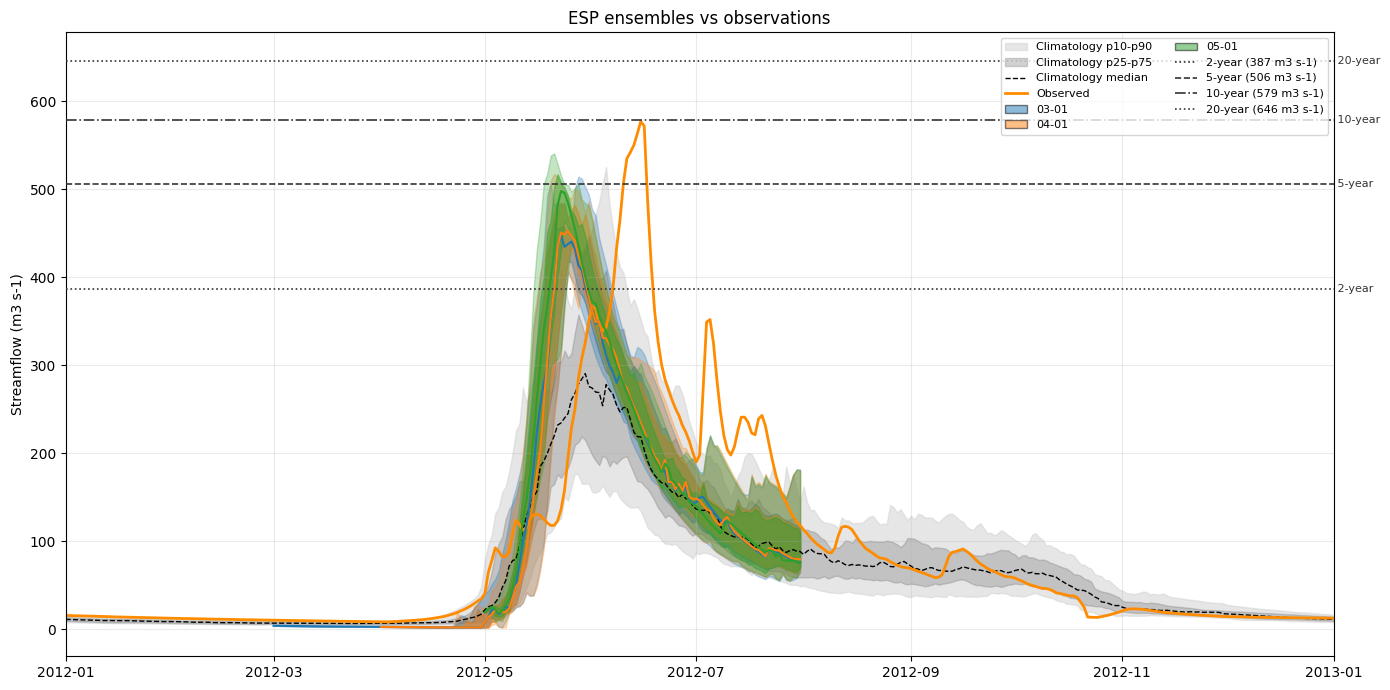

In [6]:
from snowda.io.esp_streamflow import select_return_period_thresholds
from snowda.viz.esp_streamflow import (
    plot_crps_by_lead,
    plot_ensemble_envelopes,
    plot_ensemble_forecast_separate,
    plot_peak_scores,
    plot_threshold_metrics,
)

plot_thresholds = select_return_period_thresholds(thresholds, RETURN_PERIODS)
PLOT_START = "2012-01-01"
PLOT_END = "2013-01-01"
fig, ax = plot_ensemble_envelopes(
    forecasts,
    obs,
    title="ESP ensembles vs observations",
    thresholds=plot_thresholds,
    start=PLOT_START,
    end=PLOT_END,
)

/Users/dcasson/GitHub/snowda/src/snowda/viz/esp_streamflow.py:27: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=figsize)


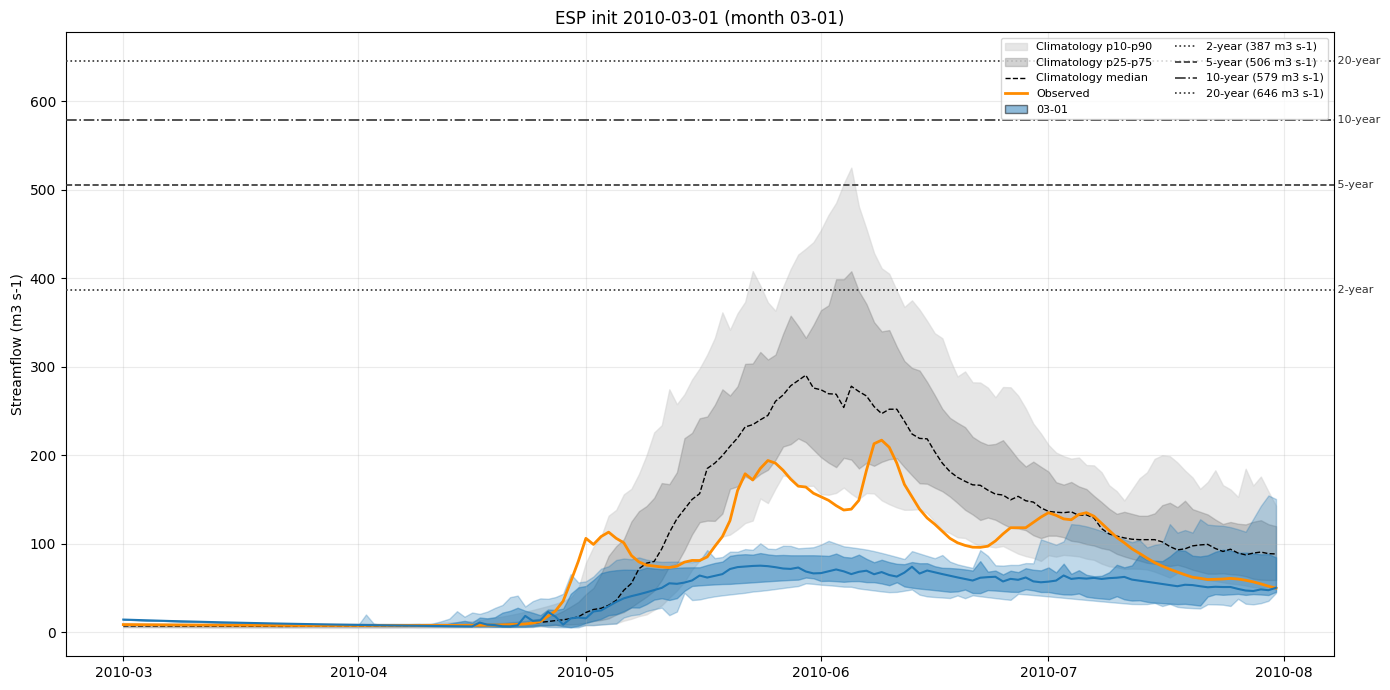

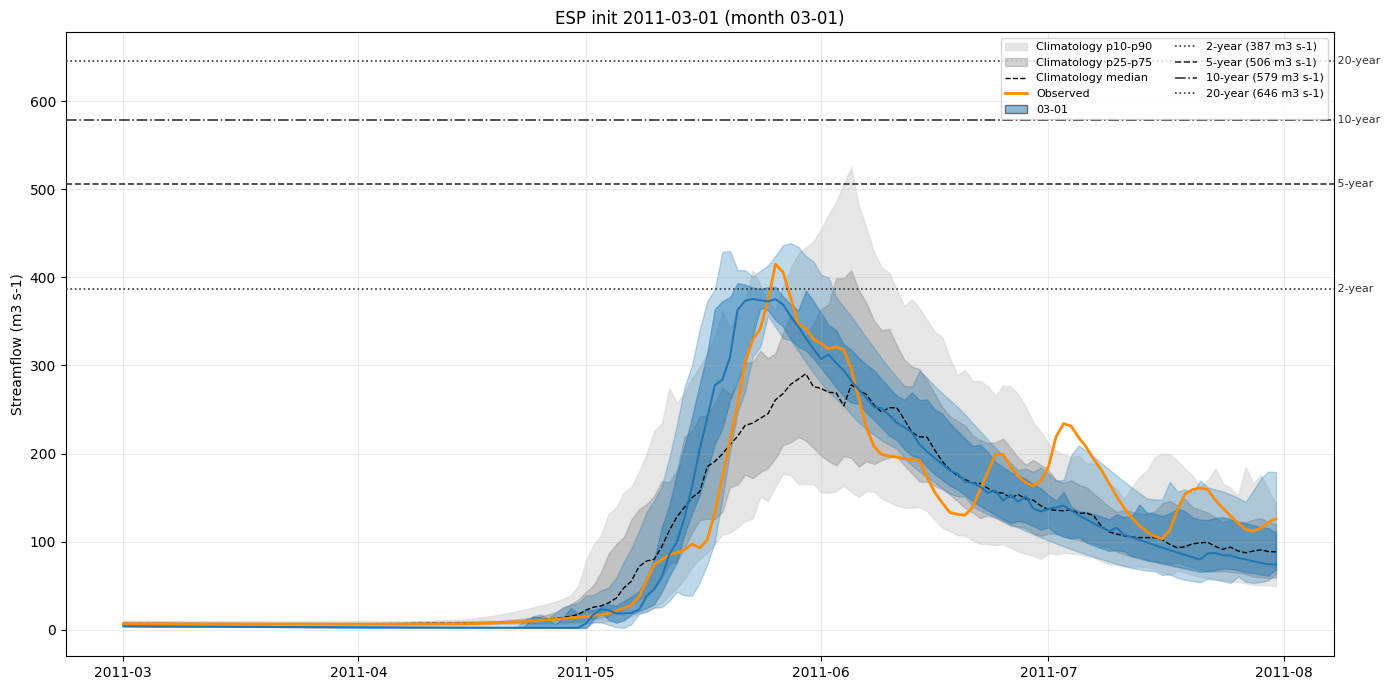

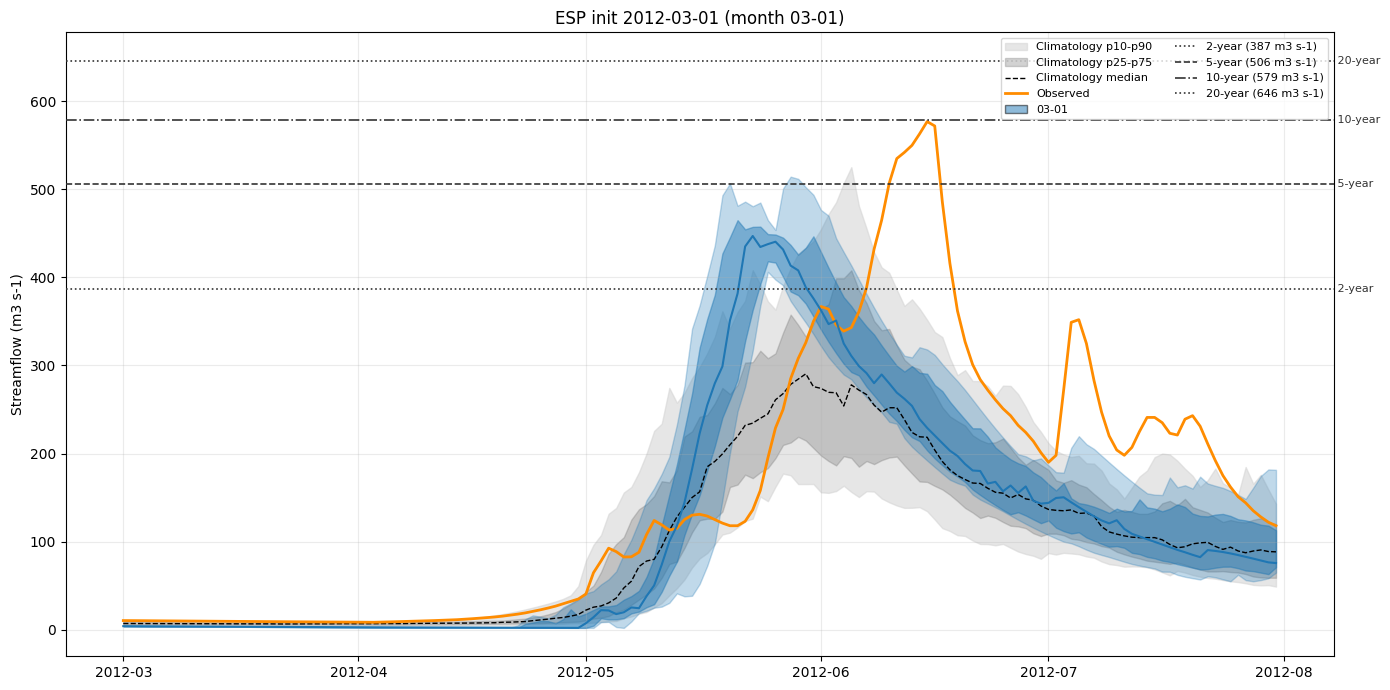

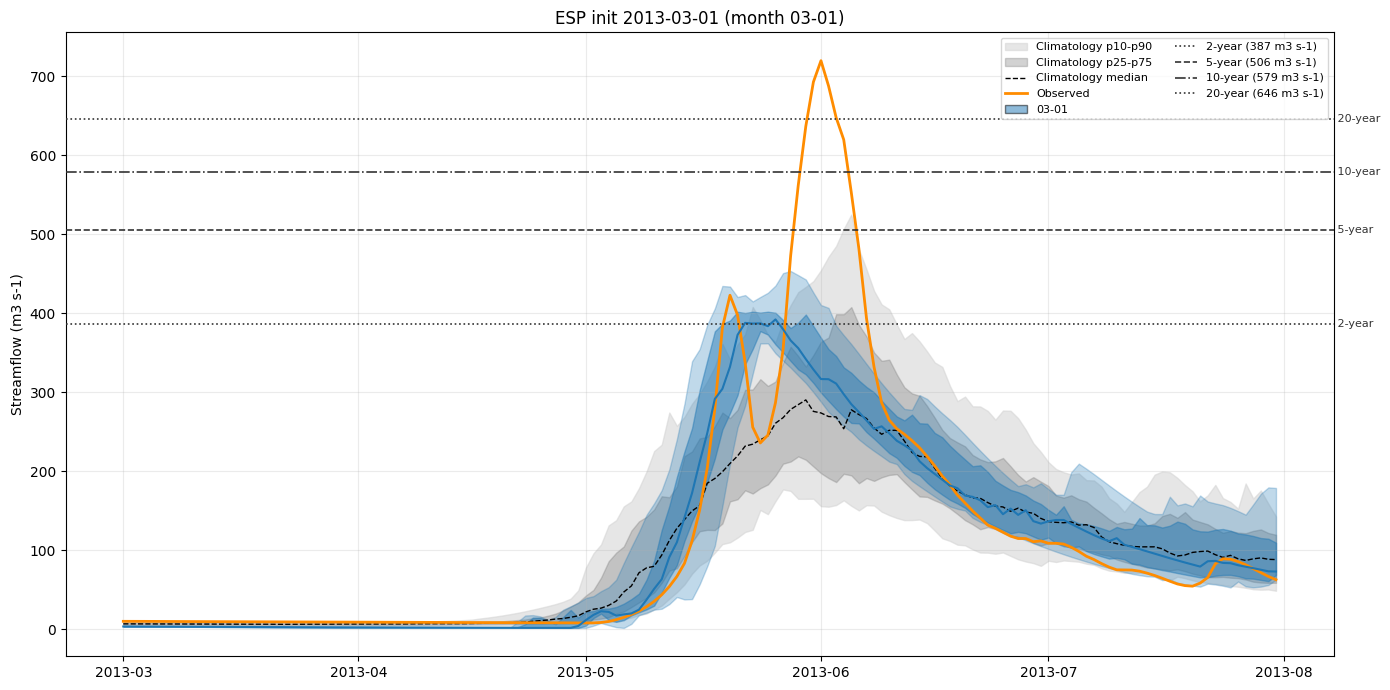

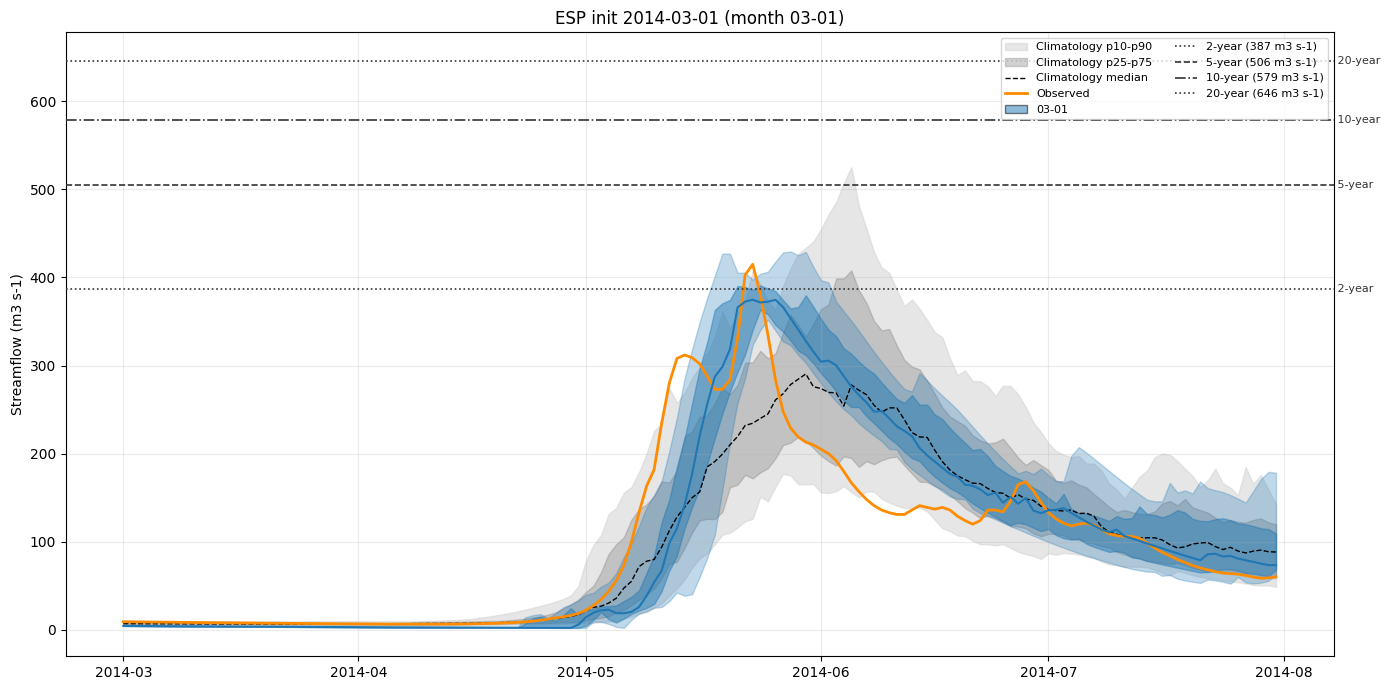

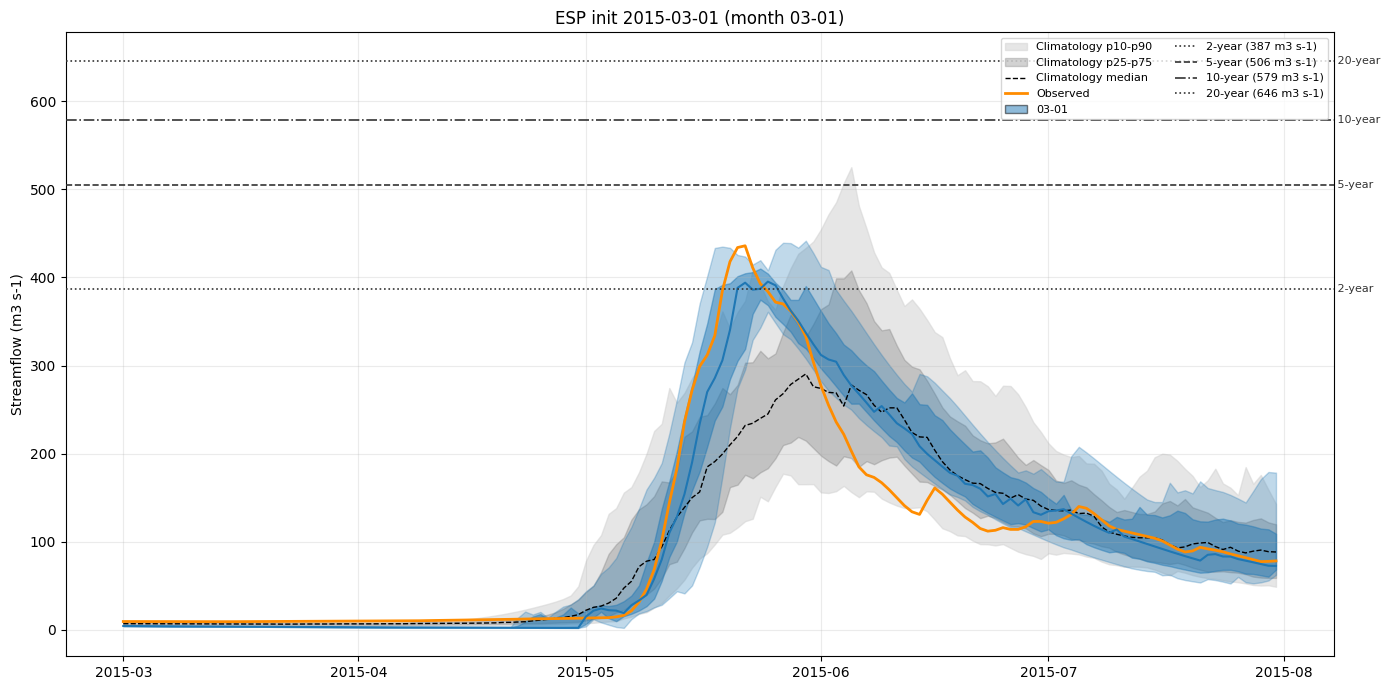

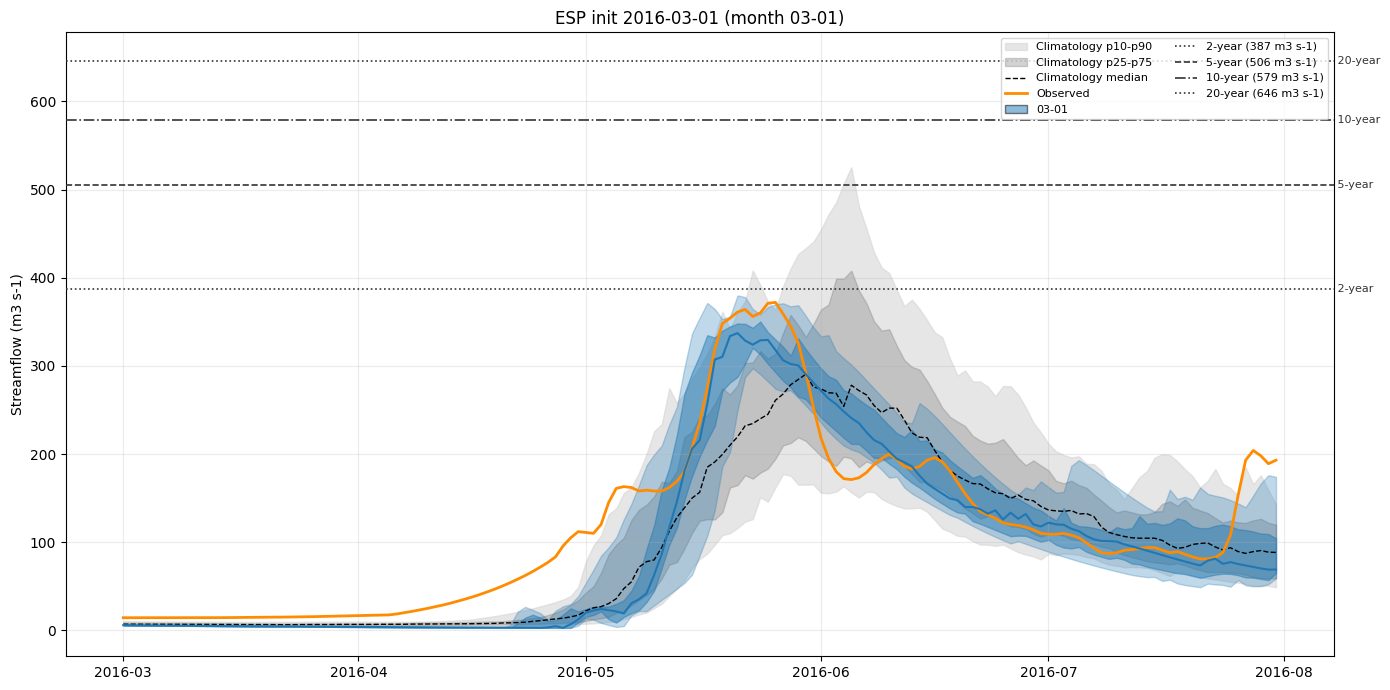

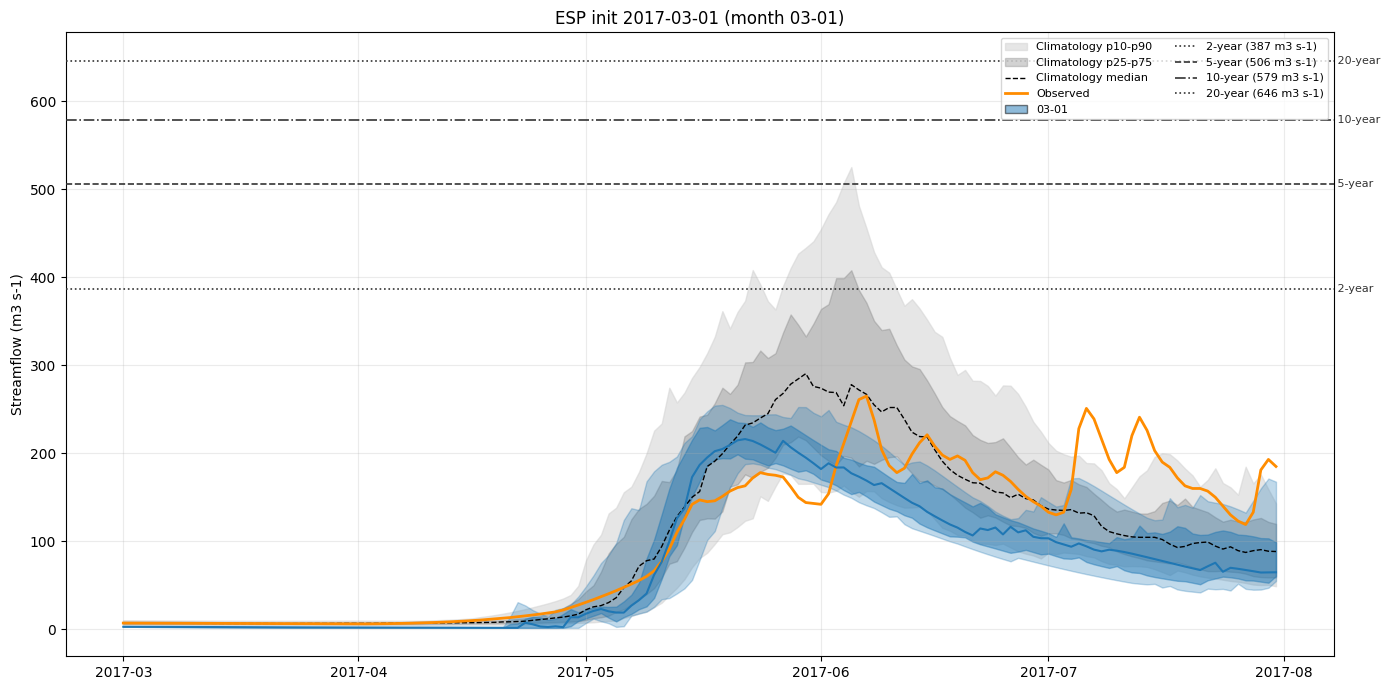

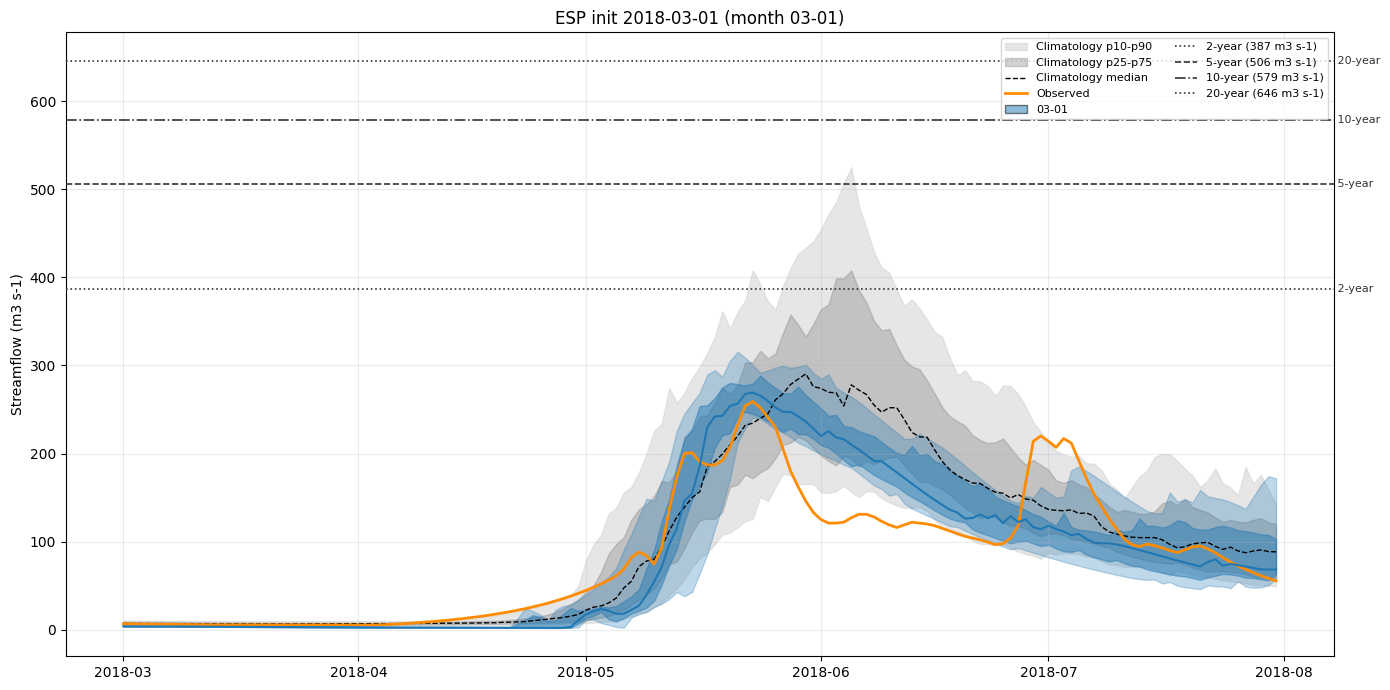

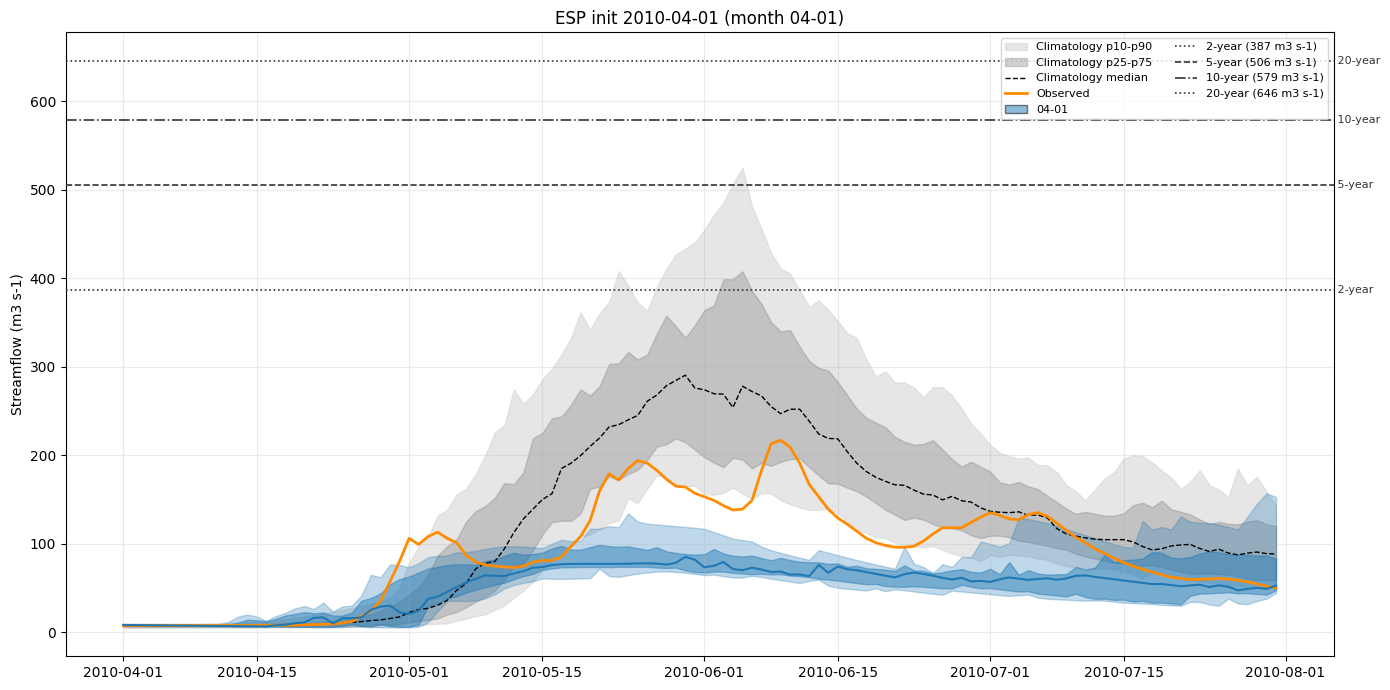

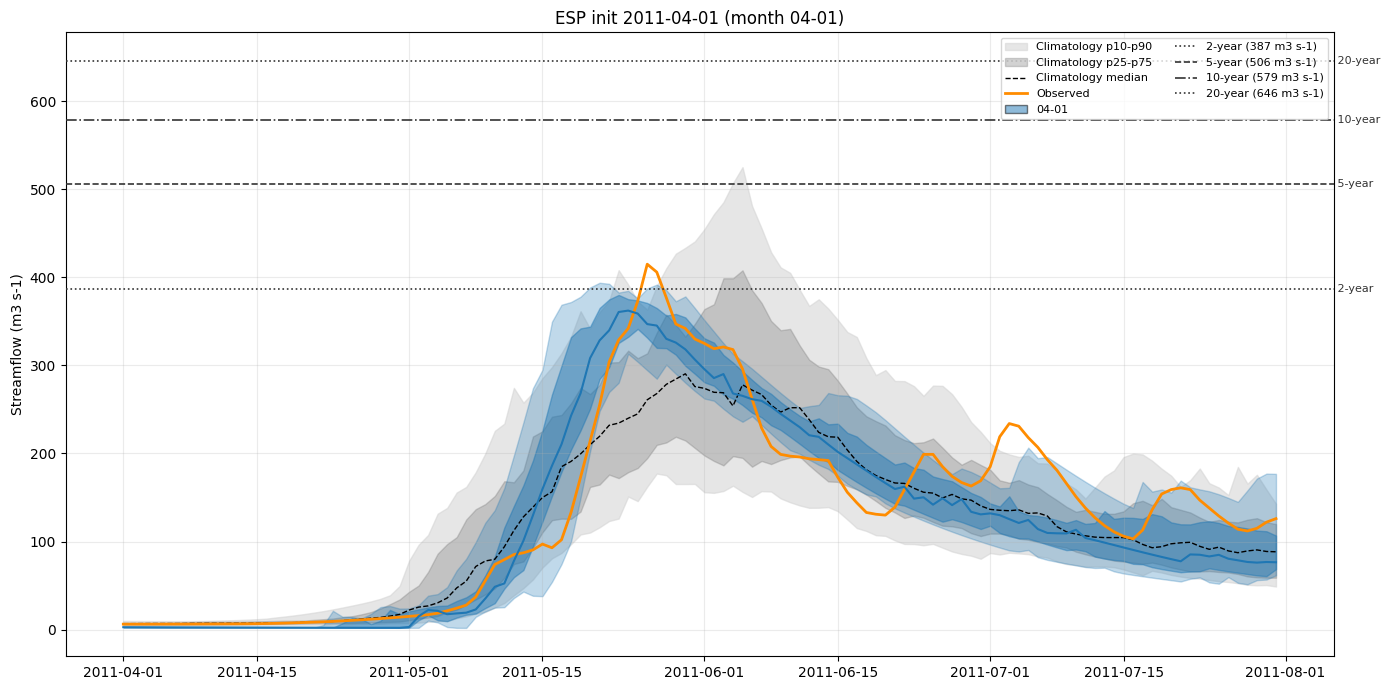

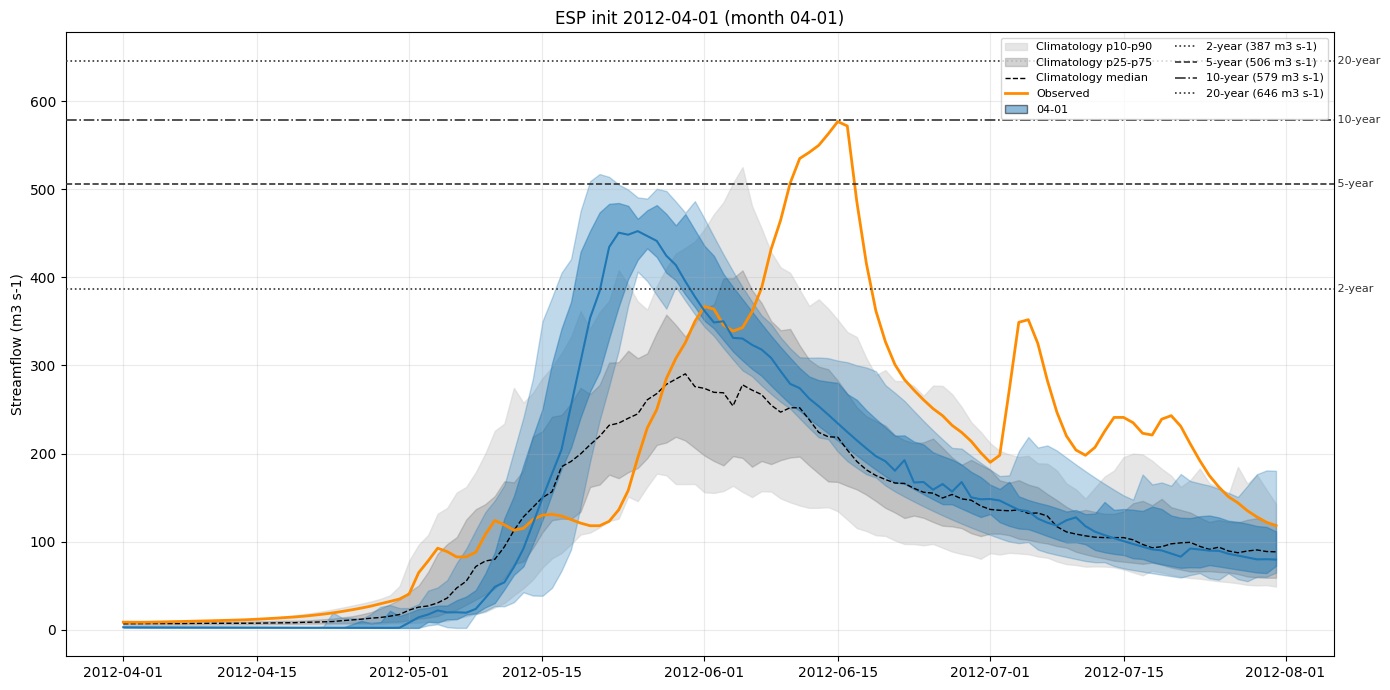

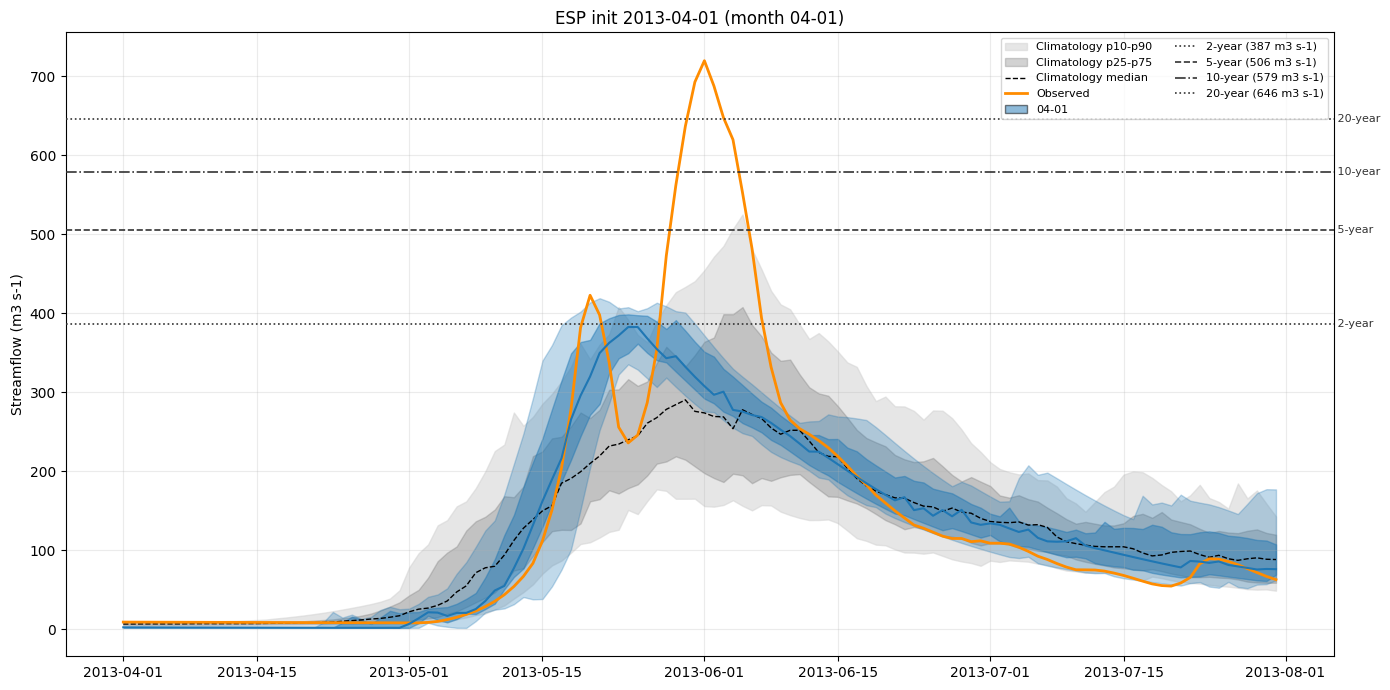

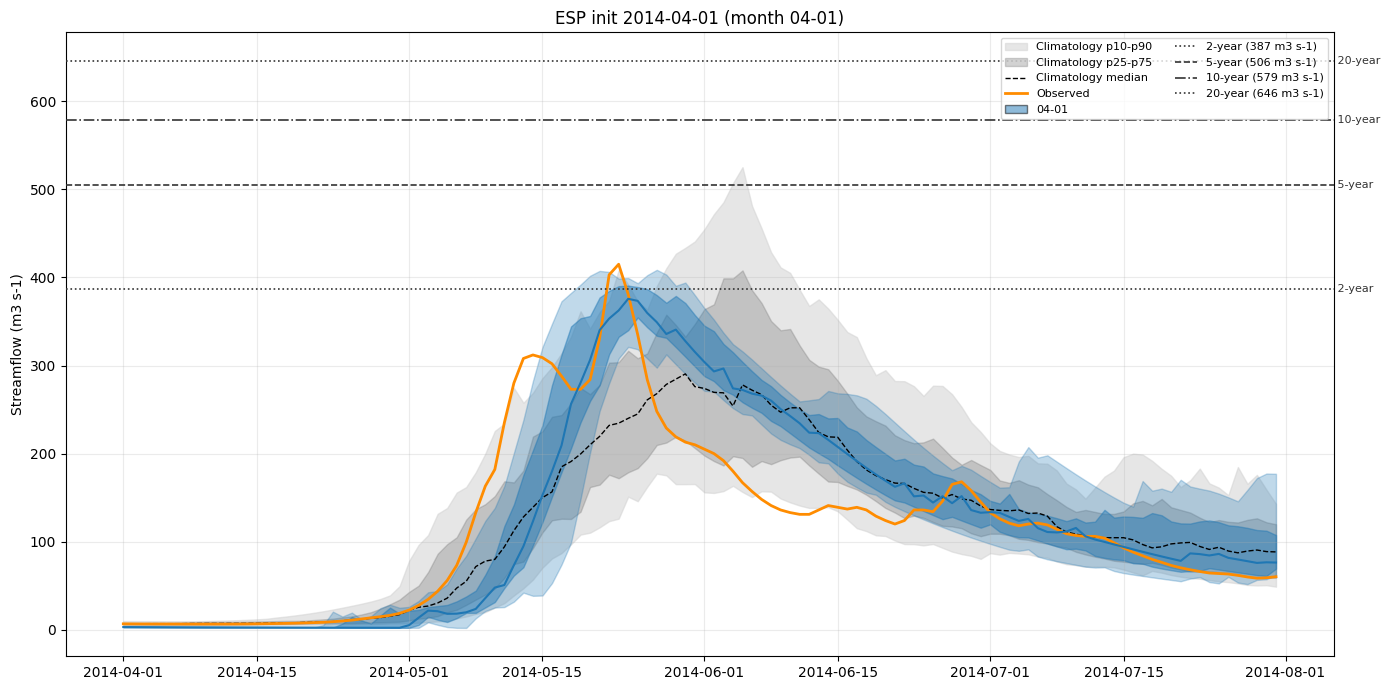

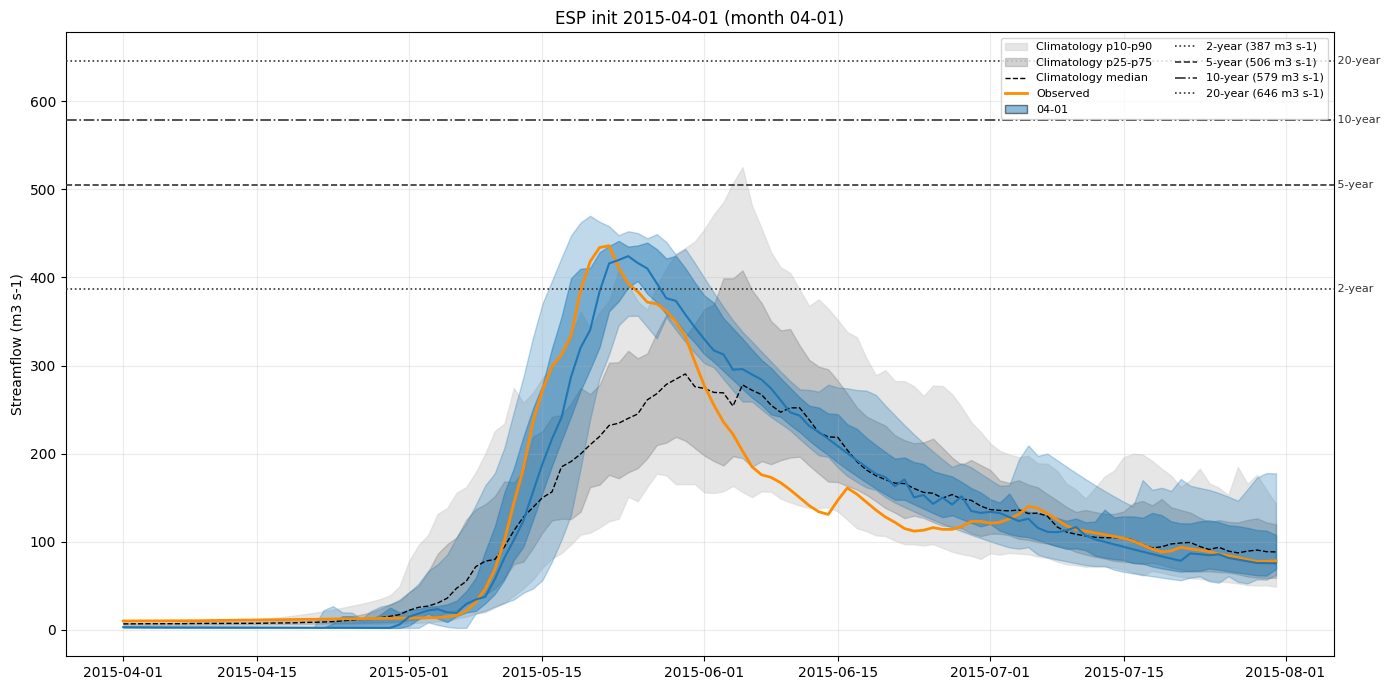

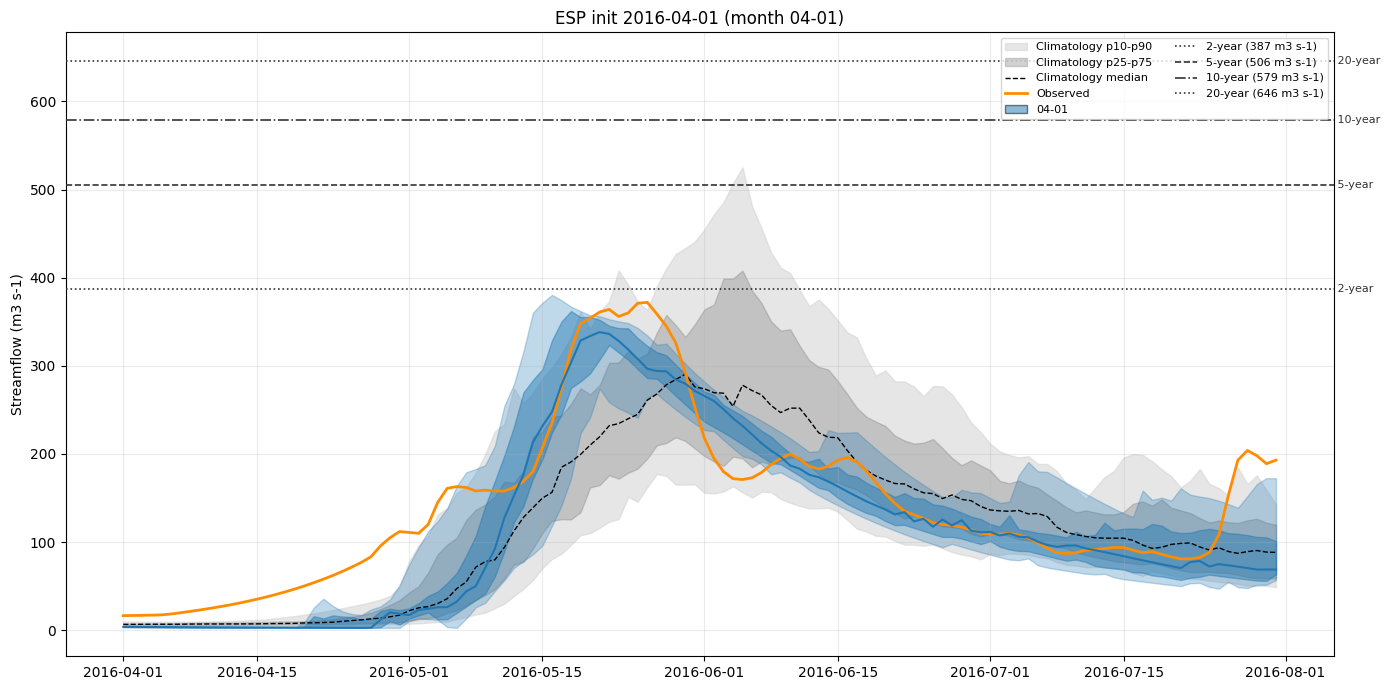

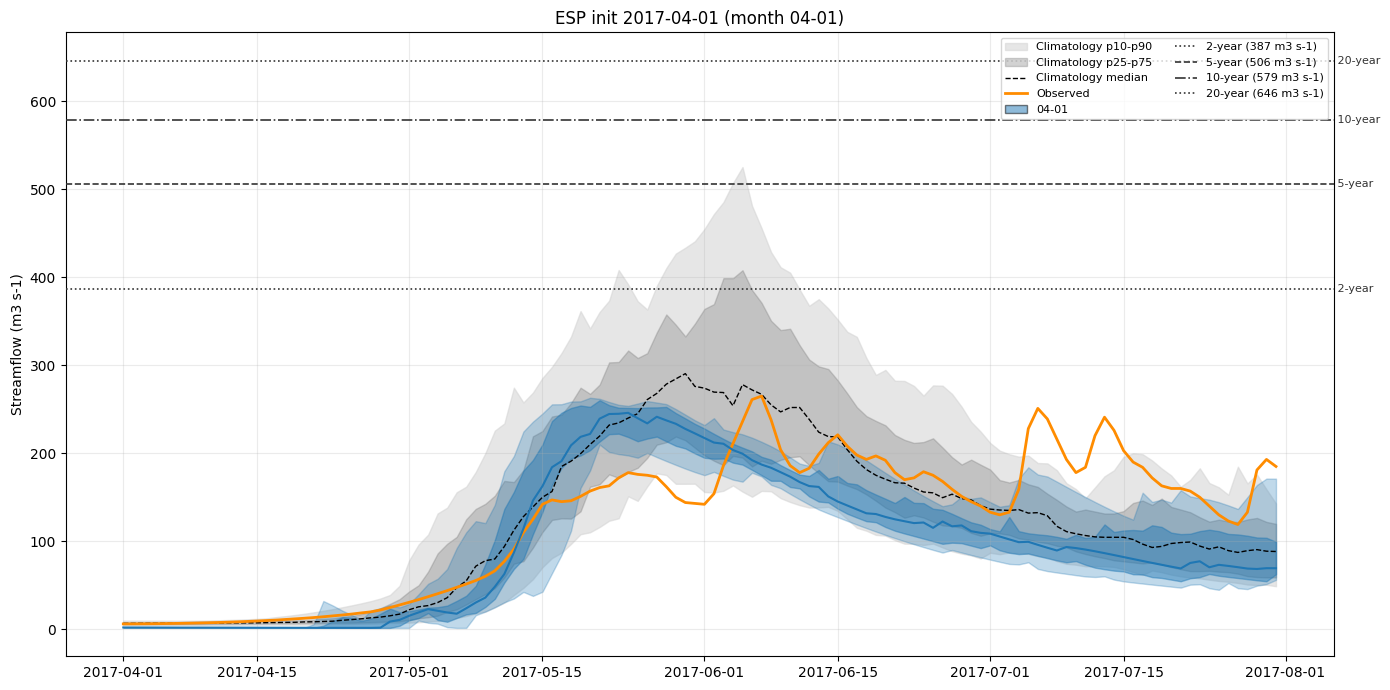

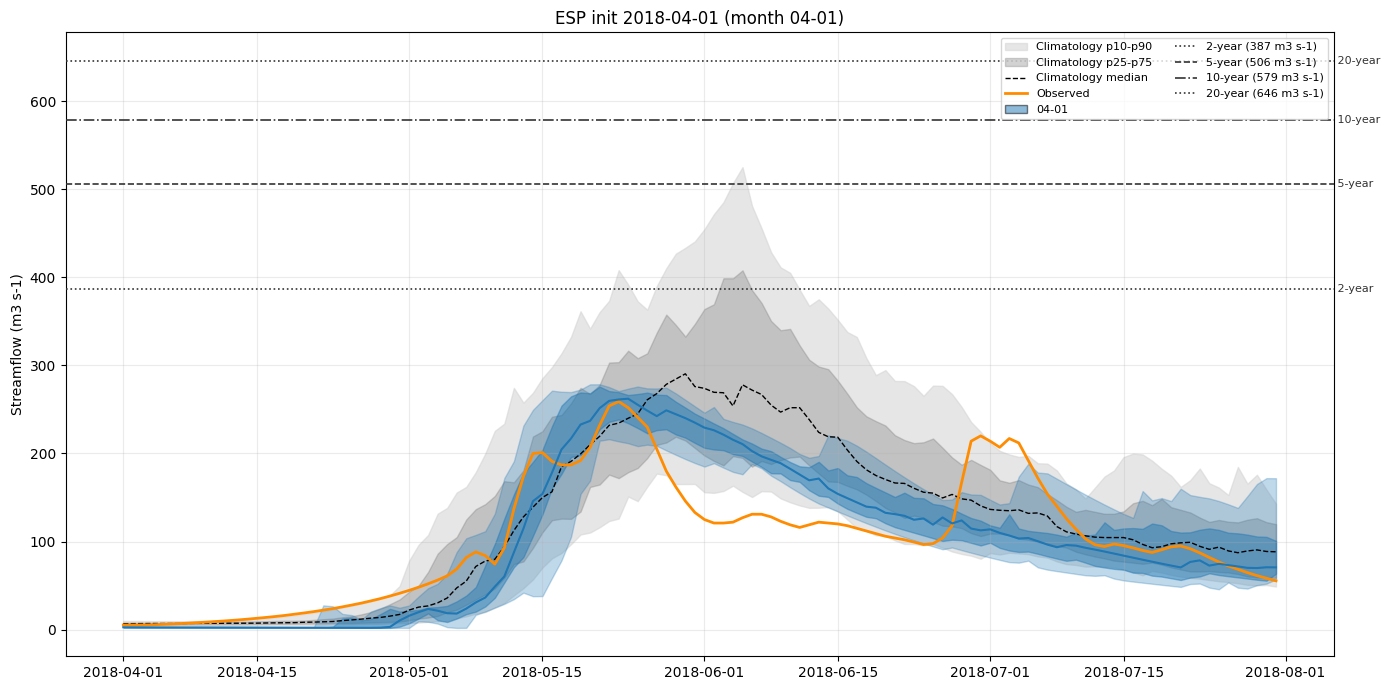

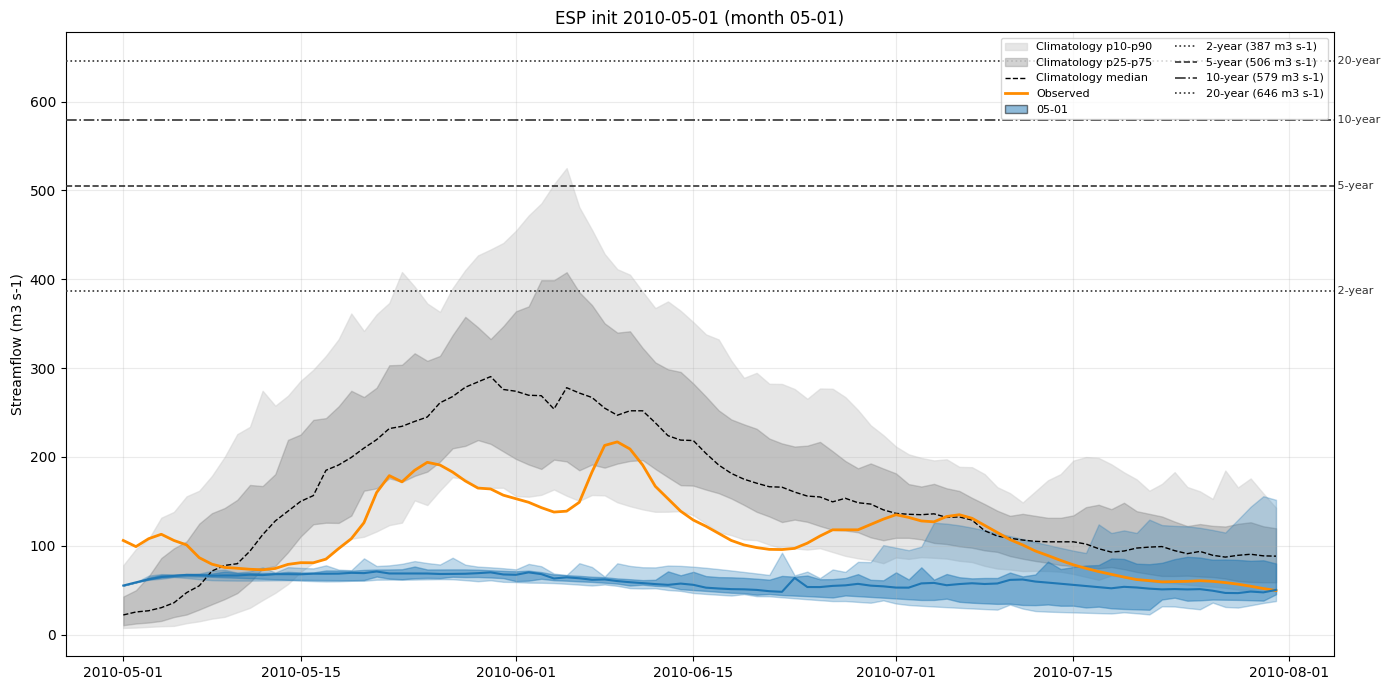

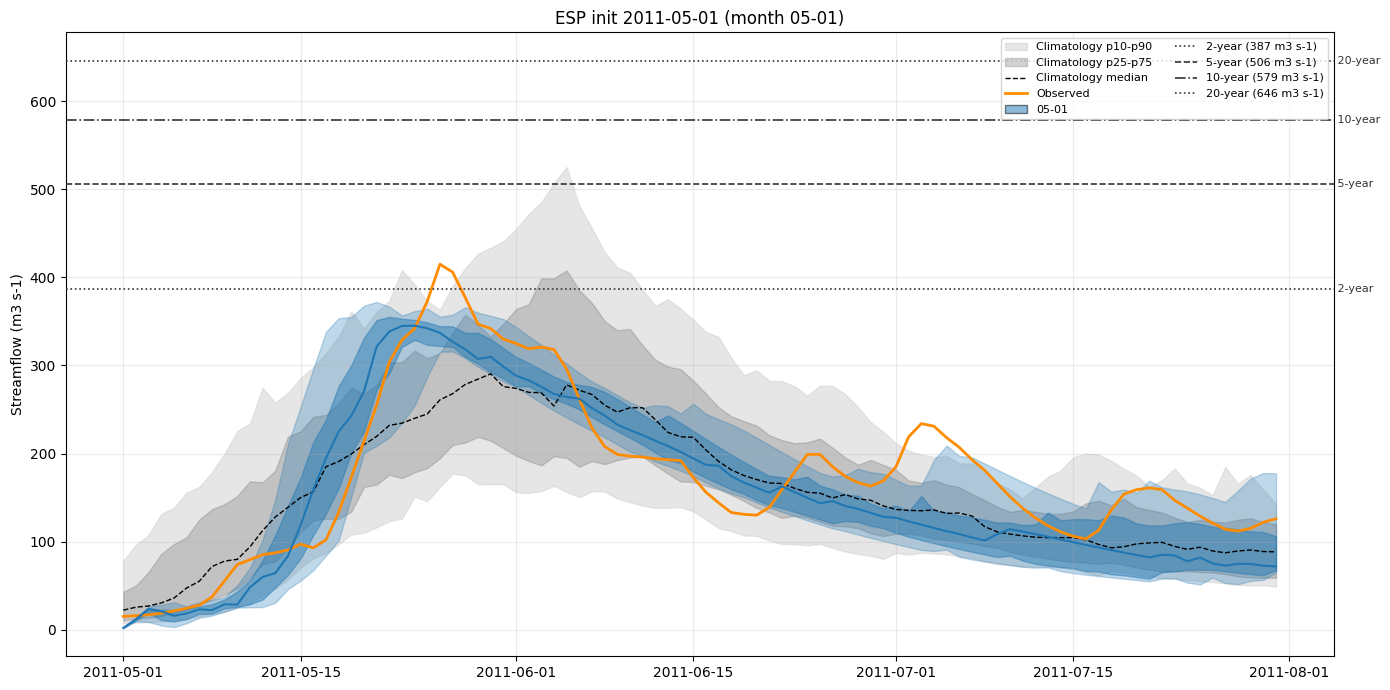

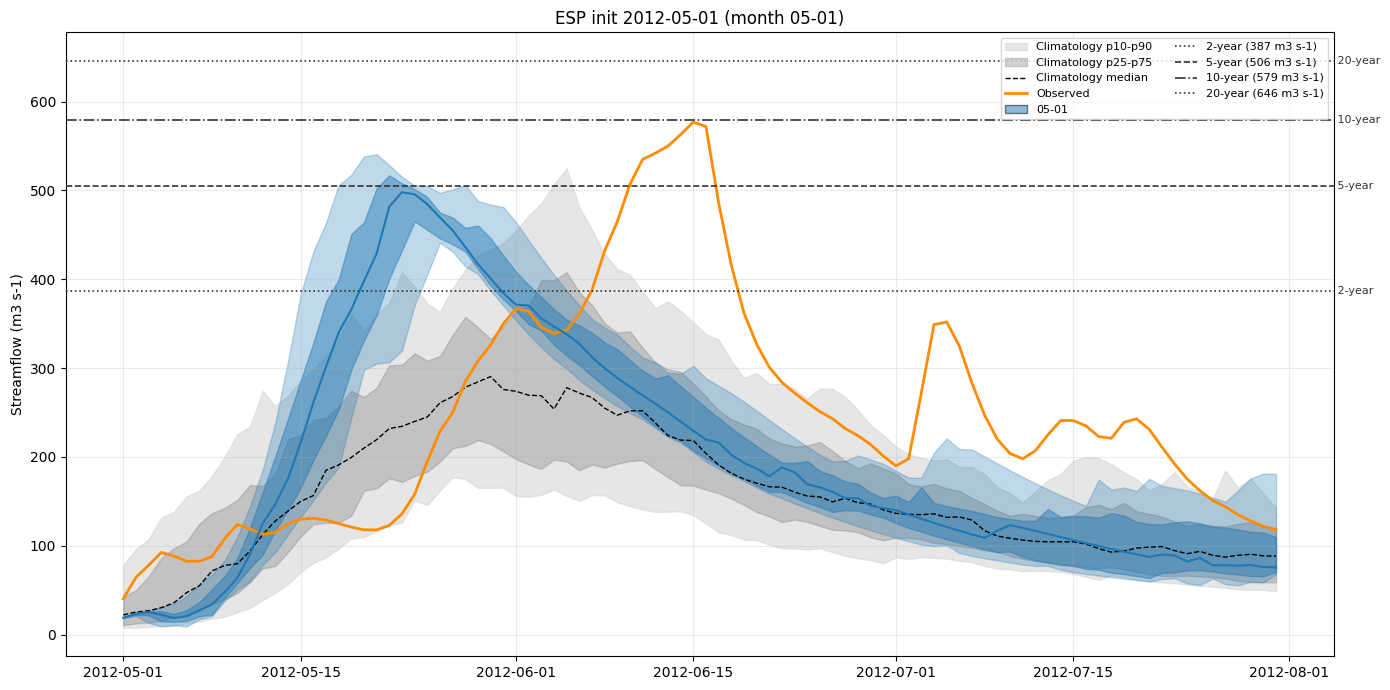

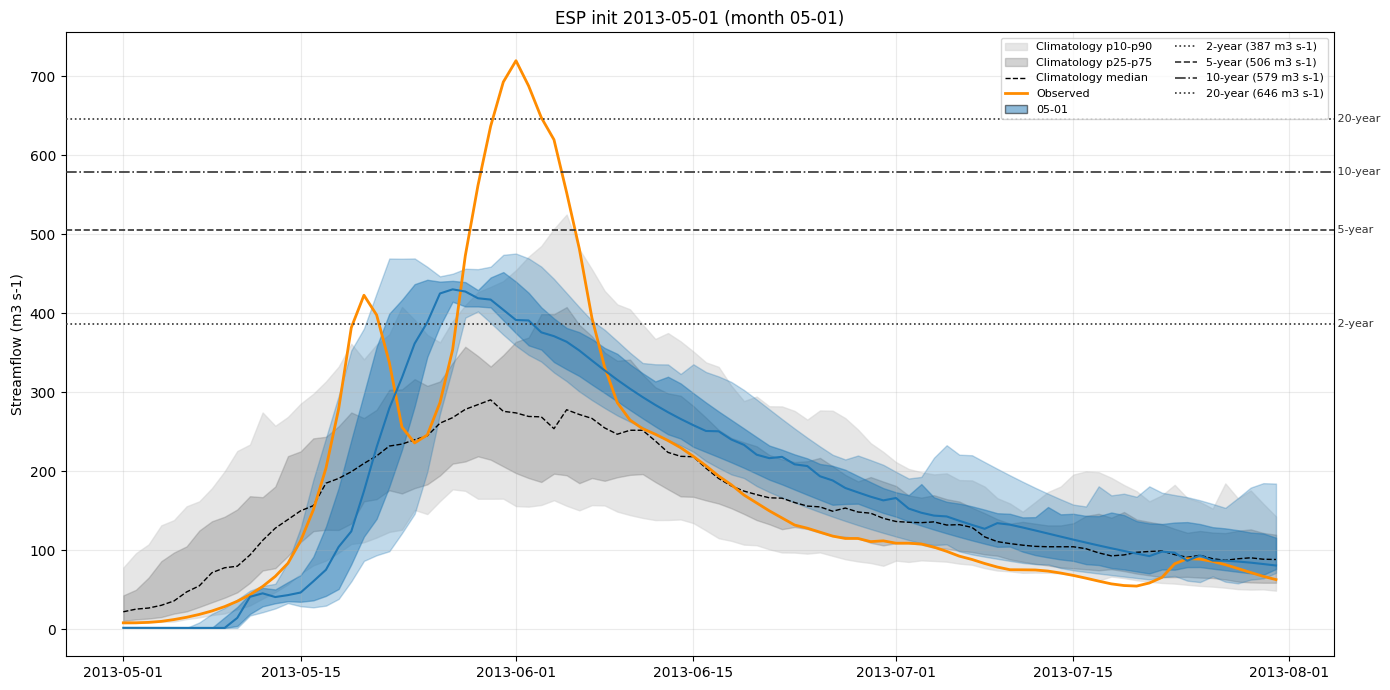

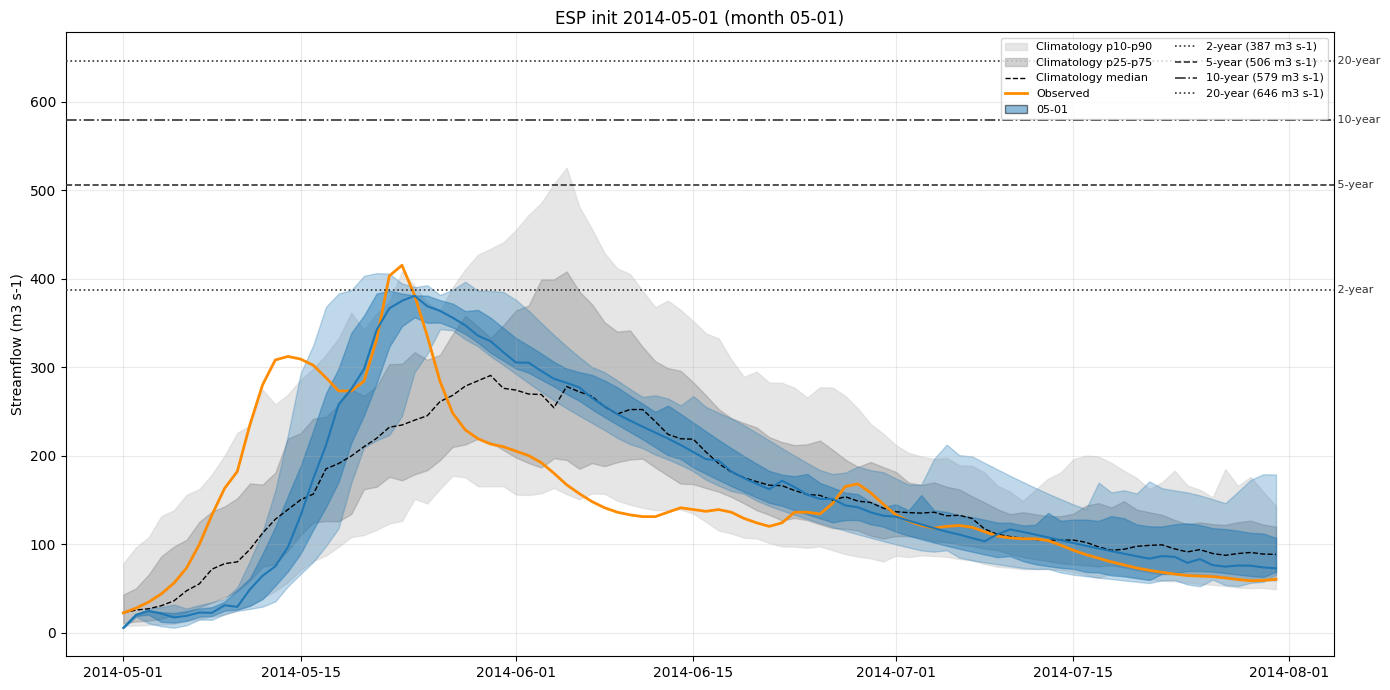

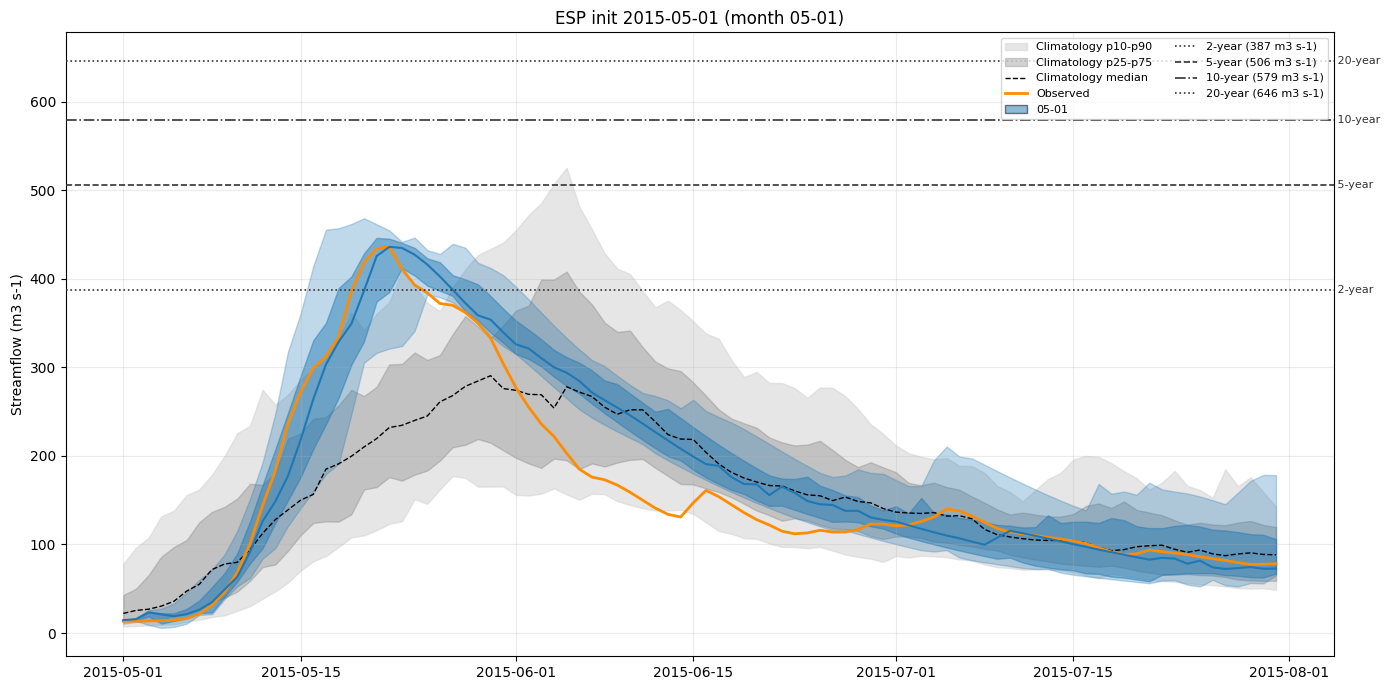

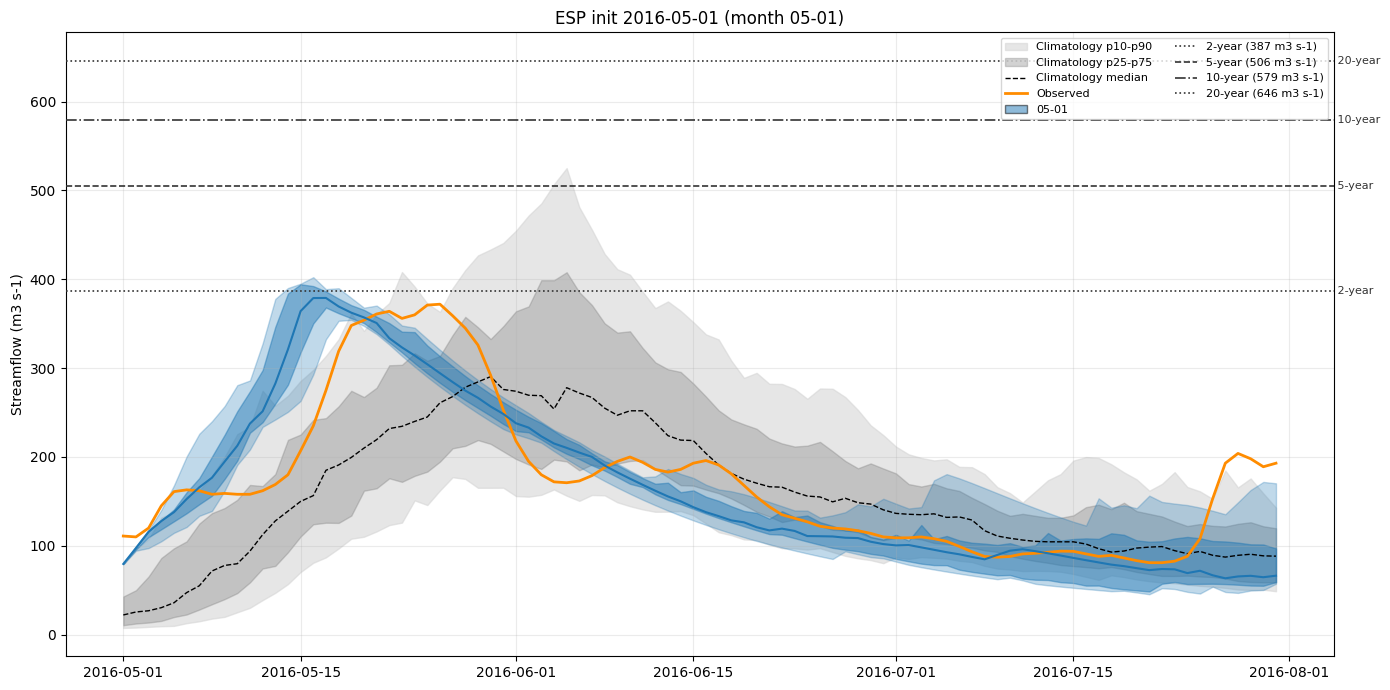

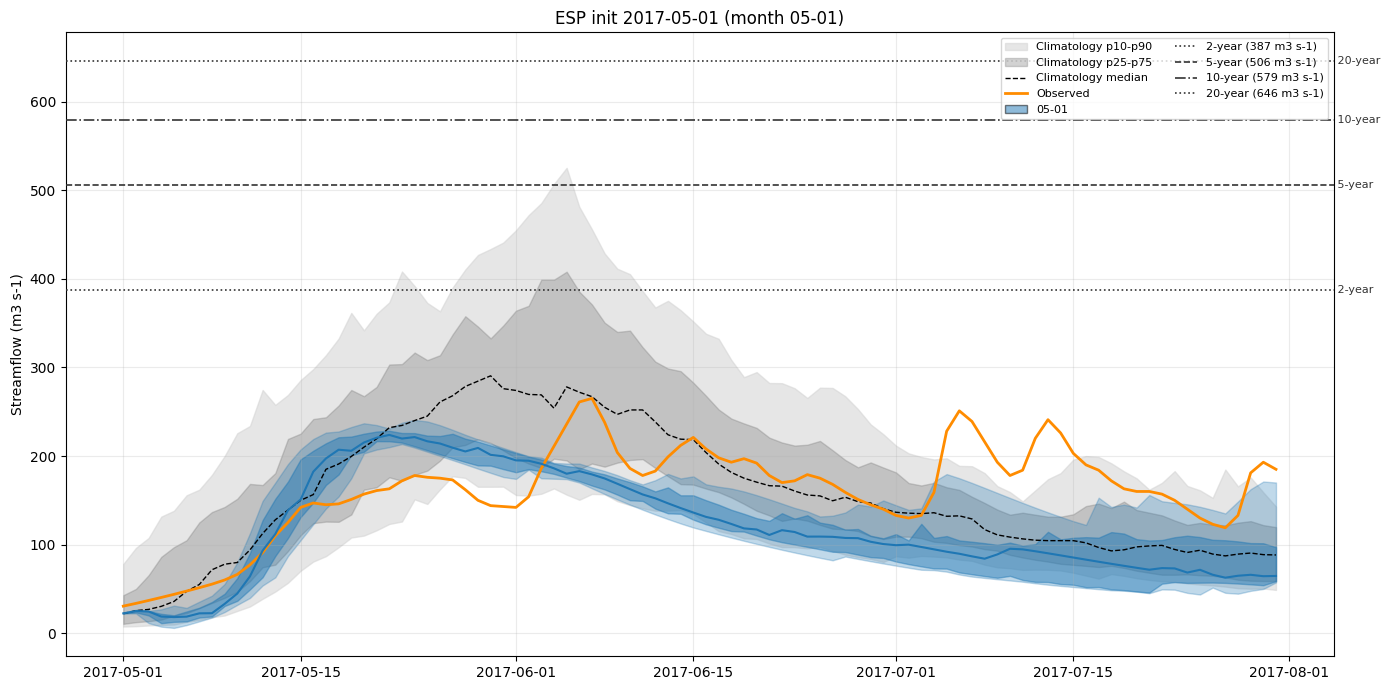

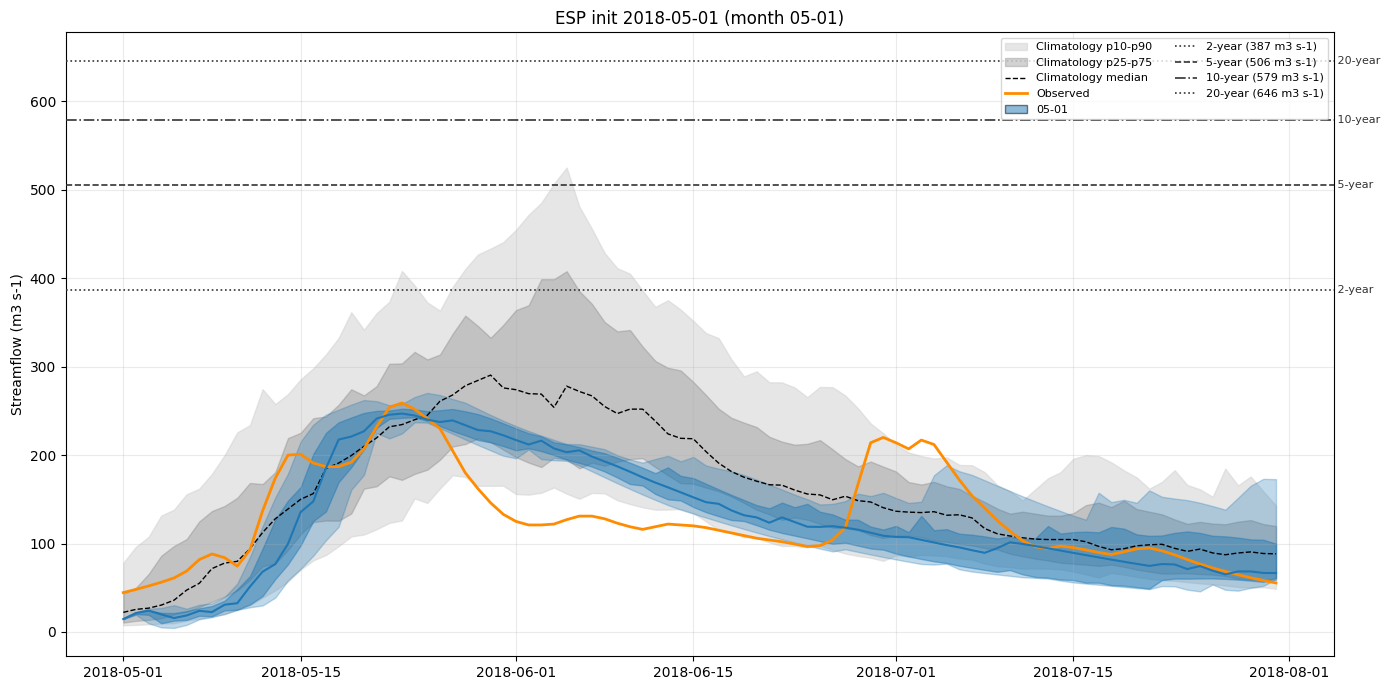

In [8]:
from IPython.display import display

for forecast in forecasts:
    fig, ax = plot_ensemble_forecast_separate(
        forecast, obs, thresholds=plot_thresholds
    )

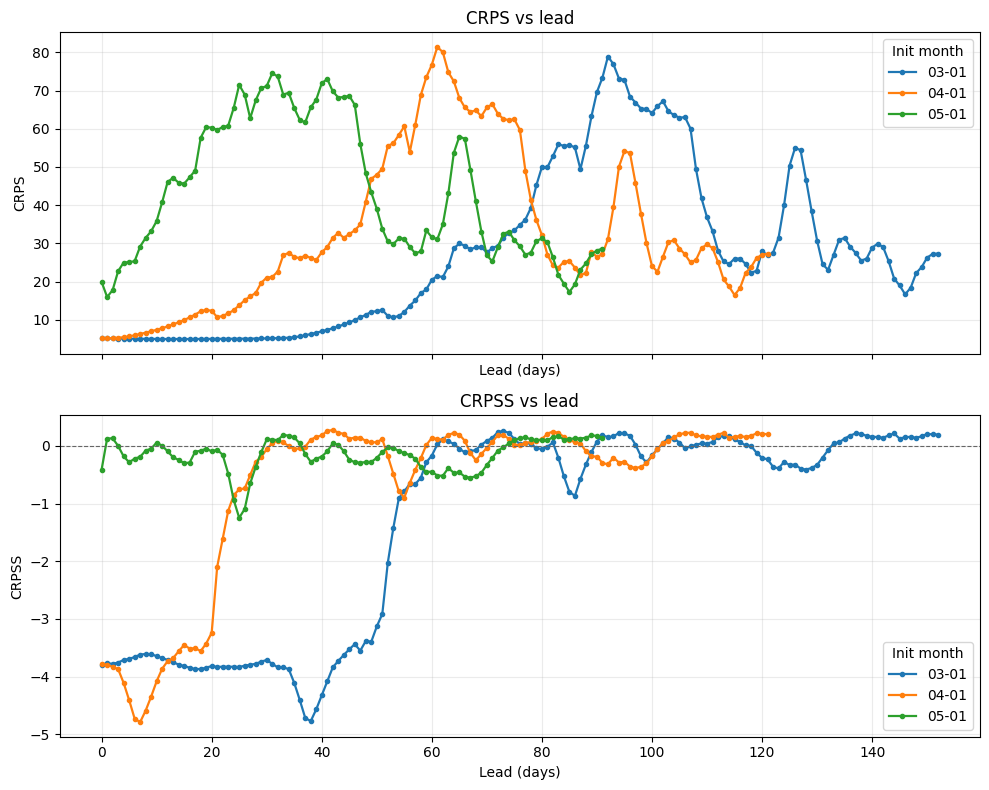

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
plot_crps_by_lead(metrics, ax=axes[0], skill=False)
plot_crps_by_lead(metrics, ax=axes[1], skill=True)
fig.tight_layout()

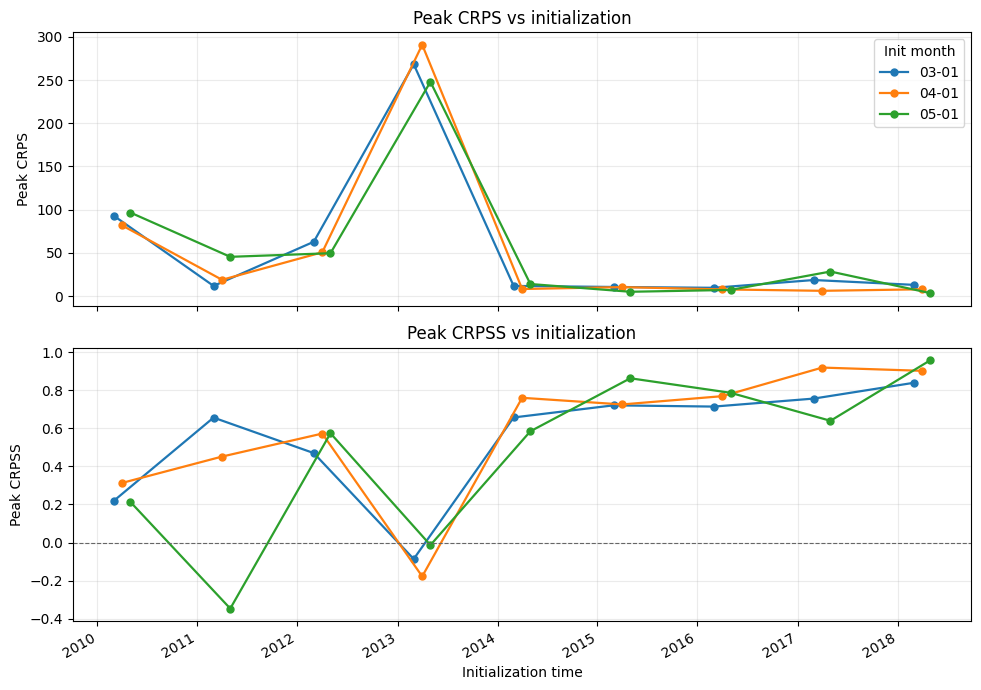

In [10]:
fig = plot_peak_scores(metrics)

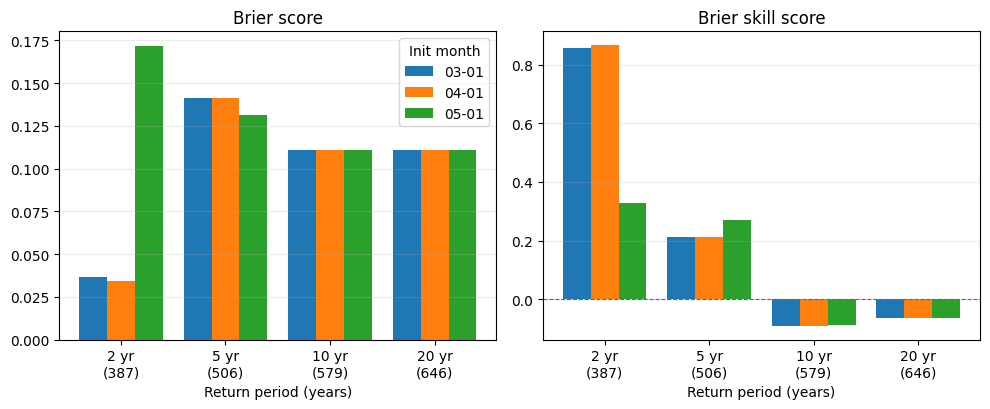

In [11]:
fig = plot_threshold_metrics(metrics)

## Reliability and ROC

Both diagrams use the peak-over-horizon ensemble probability: the fraction of members whose peak flow exceeds `Yp`, compared with whether the observed peak exceeds that same threshold. One panel per return period and one curve per initiation month. Empty reliability bins are omitted, and marker area shows how many forecasts fell in the bin.

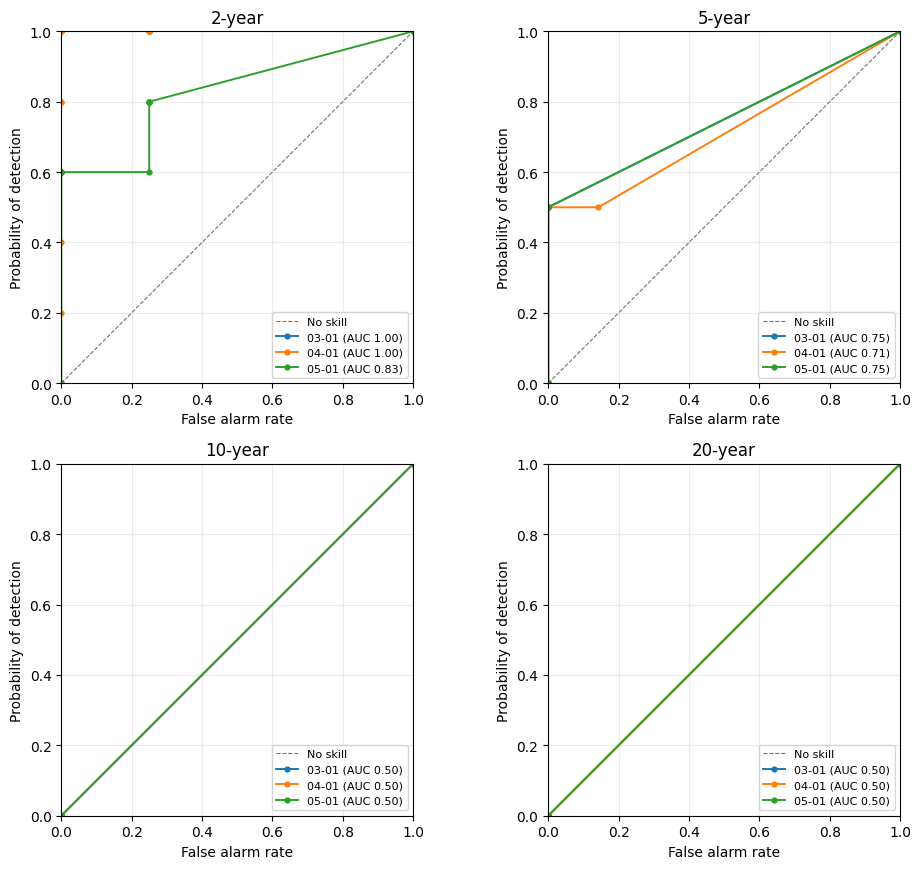

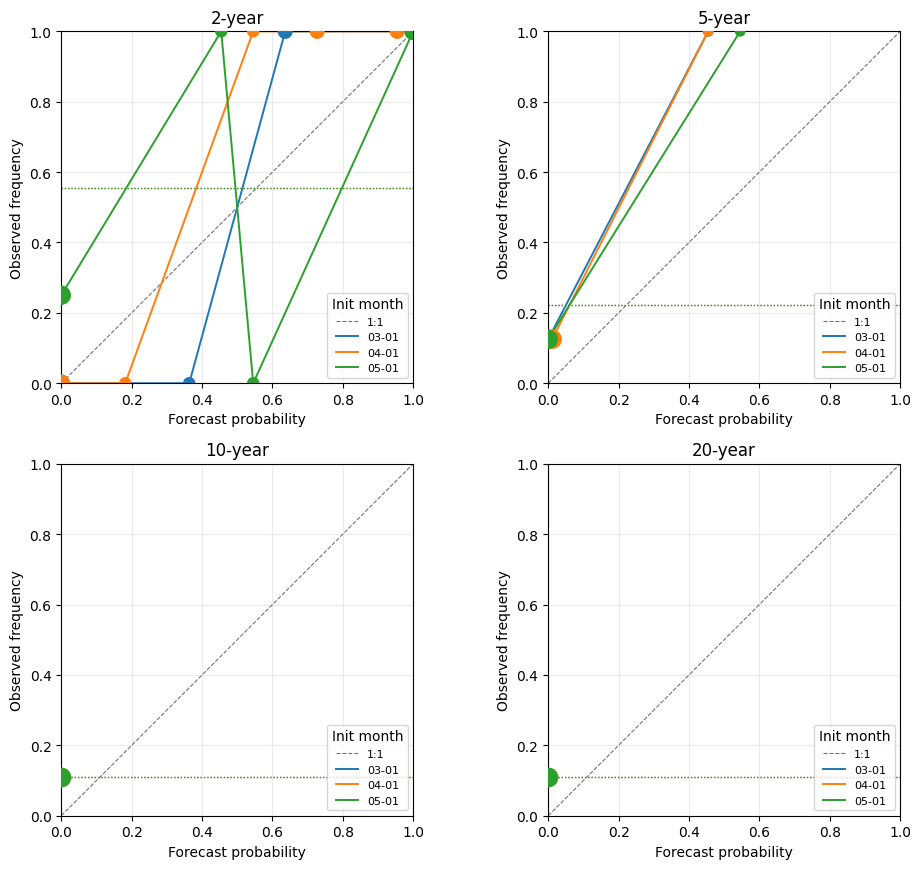

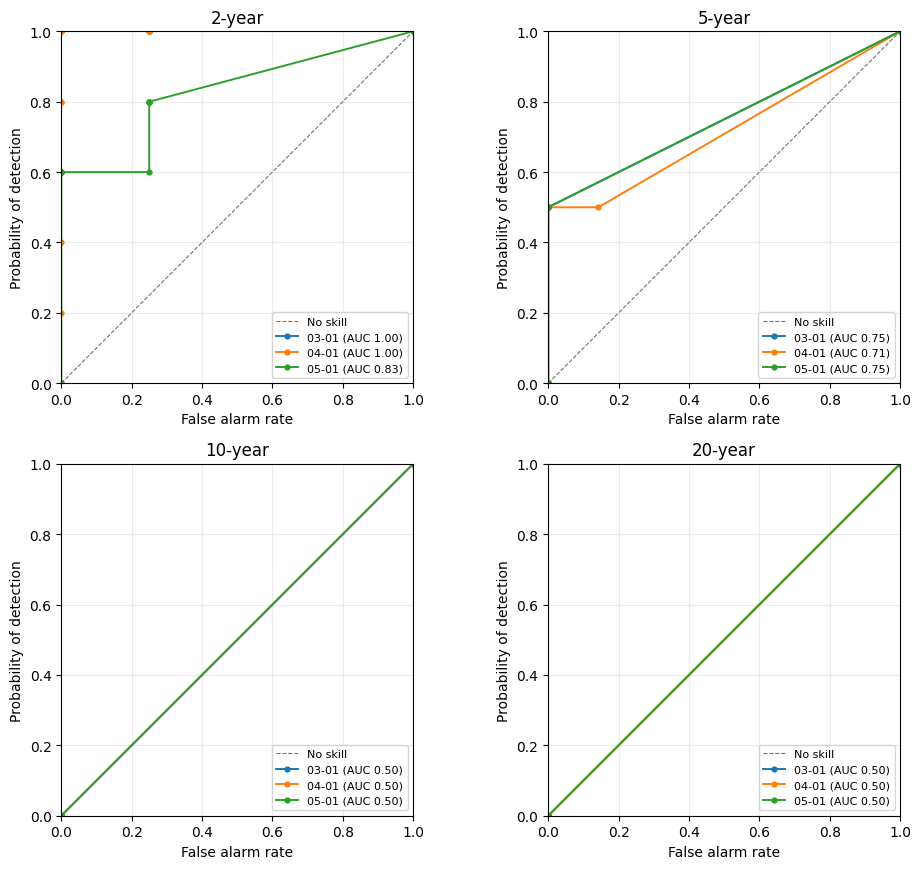

In [12]:
from snowda.adapters.scores import reliability_diagram, roc_diagram
from snowda.viz.esp_streamflow import plot_reliability_diagram, plot_roc_diagram

reliability = reliability_diagram(
    metrics["event_probability"],
    metrics["event_observed"],
)
roc = roc_diagram(
    metrics["event_probability"],
    metrics["event_observed"],
)
plot_reliability_diagram(reliability)
plot_roc_diagram(roc)

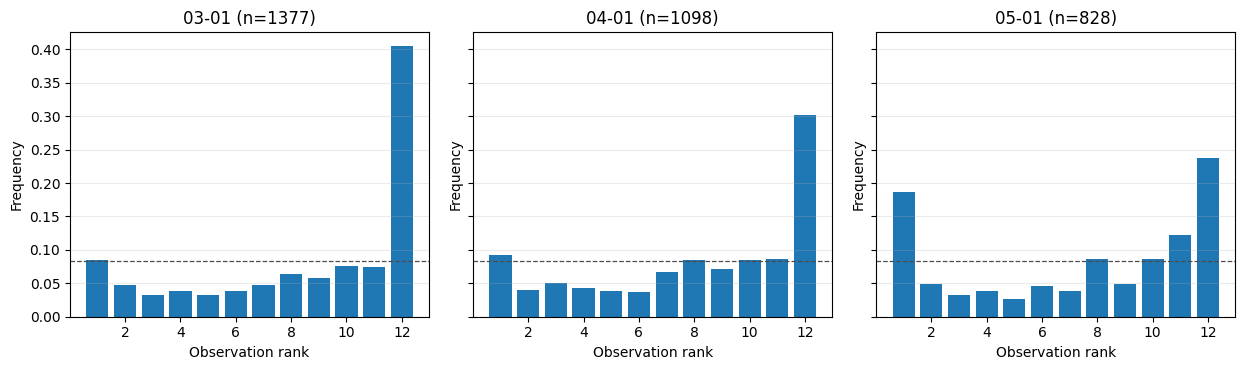

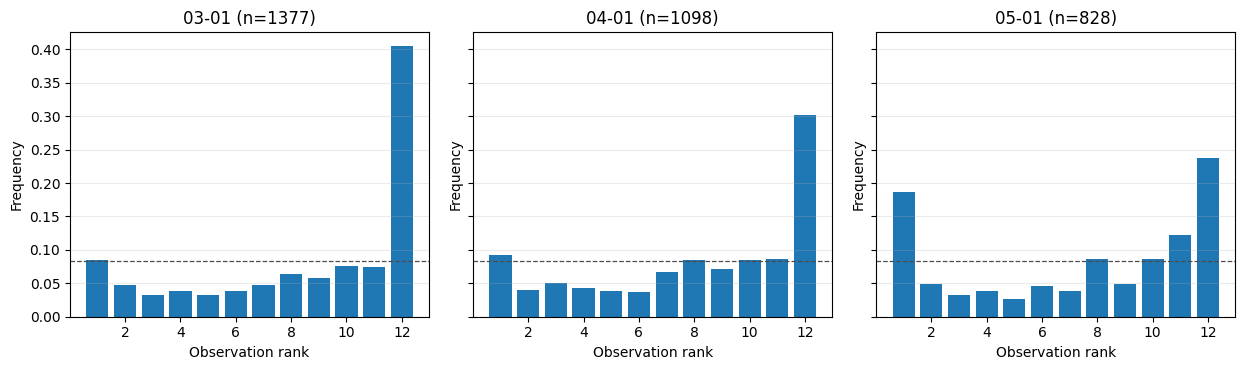

In [13]:
from snowda.viz.esp_streamflow import plot_rank_histogram

plot_rank_histogram(metrics)

## Write artifacts (optional)

Writes `metrics.nc` and `metrics.json` into a timestamped folder under `OUTPUT_DIR`.

In [14]:
from datetime import datetime, timezone

eval_dir = OUTPUT_DIR / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
write_esp_evaluation_products(metrics, eval_dir)
print("Wrote evaluation to", eval_dir)

Wrote evaluation to /Users/dcasson/GitHub/snowda/outputs/ross_esp_streamflow_10_year_eval/20261023T032737Z
